In [10]:
import os
import shutil
import random
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, UnidentifiedImageError
from sklearn.model_selection import train_test_split
from keras.models import Sequential
from keras.layers import Dense, Flatten, Dropout, Input
from keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.optimizers import RMSprop
from keras.callbacks import EarlyStopping
from keras.regularizers import l2

In [4]:
def get_valid(file_path):
    correct_files = []
    for name in os.listdir(file_path):
        try:
            img = Image.open(file_path + "/" + name)
            correct_files.append(name)
        except UnidentifiedImageError:
            pass
    return correct_files

In [5]:
classes = ['Cat', 'Dog']
original_cat_path = 'PetImages/Cat'
original_dog_path = 'PetImages/Dog'

original_cat = get_valid(original_cat_path)
original_dog = get_valid(original_dog_path)

random.seed(101)
random.shuffle(original_cat)
random.shuffle(original_dog)

size = min(len(original_cat), len(original_dog))
train_size = int(np.floor(0.7 * size))
valid_size = int(np.floor(0.2 * size))
test_size = size - train_size - valid_size

base_directory = 'dataset'
type_datasets = ['train', 'valid', 'test']
directories = {}

for type_dataset in type_datasets:
    directory = os.path.join(base_directory, type_dataset)
    for name_class in classes:
        animal = os.path.join(directory, name_class)
        os.makedirs(animal, exist_ok = True)
        directories[f'{type_dataset}_{name_class}'] = animal + '/'

for index, (name_cat, name_dog) in enumerate(zip(original_cat[:size], original_dog[:size])):
    if index < train_size:
        type_of_dataset = 'train'
    elif index < train_size + valid_size:
        type_of_dataset = 'valid'
    else:
        type_of_dataset = 'test'

    shutil.copyfile(src = original_cat_path + '/' + name_cat, dst = directories[f'{type_of_dataset}_Cat'] + name_cat)
    shutil.copyfile(src = original_dog_path + '/' + name_dog, dst = directories[f'{type_of_dataset}_Dog'] + name_dog)

print(f'Dog - train: {len(os.listdir(directories["train_Dog"]))}\tCat - train: {len(os.listdir(directories["train_Cat"]))}')
print(f'Dog - valid: {len(os.listdir(directories["valid_Dog"]))}\tCat - valid: {len(os.listdir(directories["valid_Cat"]))}')
print(f'Dog - test:  {len(os.listdir(directories["test_Dog"]))}\tCat - test:  {len(os.listdir(directories["test_Cat"]))}')

C:\Users\ayuru\AppData\Local\Programs\Python\Python314\Lib\site-packages\PIL\TiffImagePlugin.py:949: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Dog - train: 8749	Cat - train: 8749
Dog - valid: 2499	Cat - valid: 2499
Dog - test:  1251	Cat - test:  1251


In [7]:
img_width, img_height = 150, 150
train_data_dir = 'dataset/train/'
validation_data_dir = 'dataset/valid/'
epochs = 1000
batch_size = 64
steps_per_epoch = train_size // batch_size
validation_steps = valid_size // batch_size
patience = 5

train_datagen = ImageDataGenerator(rescale = 1./255)
test_datagen = ImageDataGenerator(rescale = 1./255)

train_generator = train_datagen.flow_from_directory(train_data_dir,
                                                    target_size = (img_height, img_width),
                                                    batch_size = batch_size, class_mode = 'binary')

validation_generator = test_datagen.flow_from_directory(validation_data_dir,
                                                        target_size = (img_height, img_width),
                                                        batch_size = batch_size, class_mode = 'binary')

train_datagen_augmentation = ImageDataGenerator(rescale = 1./255,
                                                shear_range = 0.2,
                                                zoom_range = 0.2,
                                                rotation_range = 30,
                                                horizontal_flip = True)

train_generator_augmentation = train_datagen_augmentation.flow_from_directory(train_data_dir,
                                                                              target_size = (img_height, img_width),
                                                                              batch_size = batch_size, class_mode = 'binary')

Found 17498 images belonging to 2 classes.
Found 4998 images belonging to 2 classes.
Found 17498 images belonging to 2 classes.


In [8]:
models = []

os.makedirs("history", exist_ok = True)
os.makedirs("charts", exist_ok = True)

In [11]:
model_1 = Sequential()
model_1.add(Input(shape = (150, 150, 3)))

# Block 1
model_1.add(Conv2D(filters = 16, kernel_size = (3, 3), activation = 'relu', padding = 'same', input_shape = (150, 150, 3)))
model_1.add(Conv2D(filters = 16, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_1.add(MaxPooling2D(pool_size = (2, 2)))

# Block 2
model_1.add(Conv2D(filters = 32, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_1.add(Conv2D(filters = 32, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_1.add(MaxPooling2D(pool_size = (2, 2)))

# Block 3
model_1.add(Conv2D(filters = 64, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_1.add(Conv2D(filters = 64, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_1.add(MaxPooling2D(pool_size = (2, 2)))

# Block 4
model_1.add(Conv2D(filters = 128, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_1.add(Conv2D(filters = 128, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_1.add(MaxPooling2D(pool_size = (2, 2)))

model_1.add(Flatten())
model_1.add(Dense(256, activation = 'relu'))
model_1.add(Dense(128, activation = 'relu'))
model_1.add(Dense(units = 1, activation = 'sigmoid'))

model_1.compile(loss = 'binary_crossentropy',
                optimizer = RMSprop(learning_rate = 1e-4),
                metrics = ['accuracy'])

model_1.summary()
models.append("model_1")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)                    │ (None, 150, 150, 16)        │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_9 (Conv2D)                    │ (None, 150, 150, 16)        │           2,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 75, 75, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_10 (Conv2D)                   │ (None, 75, 75, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_11 (Conv2D)                   │ (None, 75, 75, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 37, 37, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_12 (Conv2D)                   │ (None, 37, 37, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_13 (Conv2D)                   │ (None, 37, 37, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_6 (MaxPooling2D)       │ (None, 18, 18, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_14 (Conv2D)                   │ (None, 18, 18, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_15 (Conv2D)                   │ (None, 18, 18, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_7 (MaxPooling2D)       │ (None, 9, 9, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 10368)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 256)                 │       2,654,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,981,009 (11.37 MB)

 Trainable params: 2,981,009 (11.37 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
model_1_extended = Sequential()
model_1_extended.add(Input(shape = (150, 150, 3)))

# Block 1
model_1_extended.add(Conv2D(filters = 16, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_1_extended.add(Conv2D(filters = 16, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_1_extended.add(Conv2D(filters = 16, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_1_extended.add(MaxPooling2D(pool_size = (2, 2)))

# Block 2
model_1_extended.add(Conv2D(filters = 32, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_1_extended.add(Conv2D(filters = 32, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_1_extended.add(Conv2D(filters = 32, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_1_extended.add(MaxPooling2D(pool_size = (2, 2)))

# Block 3
model_1_extended.add(Conv2D(filters = 64, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_1_extended.add(Conv2D(filters = 64, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_1_extended.add(Conv2D(filters = 64, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_1_extended.add(MaxPooling2D(pool_size = (2, 2)))

# Block 4
model_1_extended.add(Conv2D(filters = 128, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_1_extended.add(Conv2D(filters = 128, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_1_extended.add(Conv2D(filters = 128, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_1_extended.add(MaxPooling2D(pool_size = (2, 2)))

model_1_extended.add(Flatten())
model_1_extended.add(Dense(256, activation = 'relu'))
model_1_extended.add(Dense(128, activation = 'relu'))
model_1_extended.add(Dense(units = 1, activation = 'sigmoid'))

model_1_extended.compile(loss = 'binary_crossentropy',
                         optimizer = RMSprop(learning_rate = 1e-4),
                         metrics = ['accuracy'])

es = EarlyStopping(patience = patience, monitor = 'val_accuracy', mode = 'max', restore_best_weights = True)

In [16]:
history_model_1_extended = model_1_extended.fit(
    train_generator,
    epochs = epochs,
    validation_data = validation_generator,
    callbacks = [es]
)

history_model_1_extended_df = pd.DataFrame(history_model_1_extended.history)
history_model_1_extended_csv_file = 'history/history_model_1_extended.csv'

history_model_1_extended_df.to_csv(history_model_1_extended_csv_file, index = False)

Epoch 1/1000
274/274 ━━━━━━━━━━━━━━━━━━━━ 50s 181ms/step - accuracy: 0.5648 - loss: 0.6760 - val_accuracy: 0.6345 - val_loss: 0.6383
Epoch 2/1000
274/274 ━━━━━━━━━━━━━━━━━━━━ 50s 181ms/step - accuracy: 0.6301 - loss: 0.6303 - val_accuracy: 0.6733 - val_loss: 0.5968
Epoch 3/1000
274/274 ━━━━━━━━━━━━━━━━━━━━ 51s 185ms/step - accuracy: 0.6735 - loss: 0.5932 - val_accuracy: 0.7023 - val_loss: 0.5654
Epoch 4/1000
274/274 ━━━━━━━━━━━━━━━━━━━━ 49s 178ms/step - accuracy: 0.7073 - loss: 0.5597 - val_accuracy: 0.7255 - val_loss: 0.5407
Epoch 5/1000
274/274 ━━━━━━━━━━━━━━━━━━━━ 49s 179ms/step - accuracy: 0.7258 - loss: 0.5337 - val_accuracy: 0.7389 - val_loss: 0.5222
Epoch 6/1000
274/274 ━━━━━━━━━━━━━━━━━━━━ 49s 179ms/step - accuracy: 0.7419 - loss: 0.5146 - val_accuracy: 0.7523 - val_loss: 0.5052
Epoch 7/1000
274/274 ━━━━━━━━━━━━━━━━━━━━ 49s 179ms/step - accuracy: 0.7567 - loss: 0.4940 - val_accuracy: 0.7533 - val_loss: 0.5035
Epoch 8/1000
274/274 ━━━━━━━━━━━━━━━━━━━━ 49s 177ms/step - accuracy: 

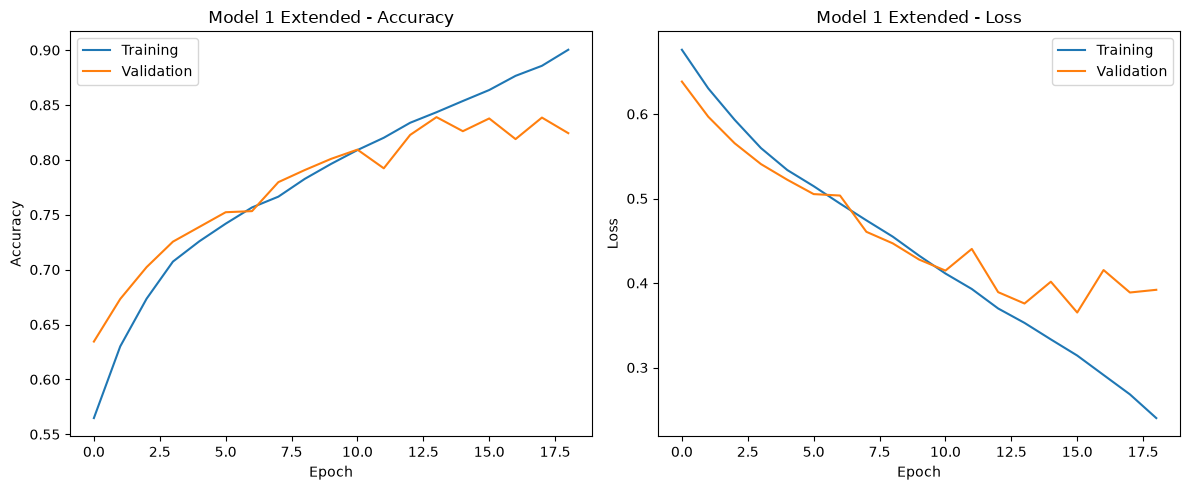

In [17]:
plt.figure(figsize = (12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_model_1_extended.history['accuracy'], label = 'Training')
plt.plot(history_model_1_extended.history['val_accuracy'], label = 'Validation')
plt.title('Model 1 Extended - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_model_1_extended.history['loss'], label = 'Training')
plt.plot(history_model_1_extended.history['val_loss'], label = 'Validation')
plt.title('Model 1 Extended - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [18]:
model_2_extended = Sequential()
model_2_extended.add(Input(shape = (150, 150, 3)))

# Block 1
model_2_extended.add(Conv2D(filters = 16, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_2_extended.add(Conv2D(filters = 16, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_2_extended.add(Conv2D(filters = 16, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_2_extended.add(MaxPooling2D(pool_size = (2, 2)))

# Block 2
model_2_extended.add(Conv2D(filters = 32, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_2_extended.add(Conv2D(filters = 32, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_2_extended.add(Conv2D(filters = 32, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_2_extended.add(MaxPooling2D(pool_size = (2, 2)))

# Block 3
model_2_extended.add(Conv2D(filters = 64, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_2_extended.add(Conv2D(filters = 64, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_2_extended.add(Conv2D(filters = 64, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_2_extended.add(MaxPooling2D(pool_size = (2, 2)))

# Block 4
model_2_extended.add(Conv2D(filters = 128, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_2_extended.add(Conv2D(filters = 128, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_2_extended.add(Conv2D(filters = 128, kernel_size = (3, 3), activation = 'relu', padding = 'same'))
model_2_extended.add(MaxPooling2D(pool_size = (2, 2)))

model_2_extended.add(Flatten())
model_2_extended.add(Dropout(0.5))
model_2_extended.add(Dense(256, activation = 'relu'))
model_2_extended.add(Dropout(0.5))
model_2_extended.add(Dense(128, activation = 'relu'))
model_2_extended.add(Dense(units = 1, activation = 'sigmoid'))

model_2_extended.compile(loss = 'binary_crossentropy',
                         optimizer = RMSprop(learning_rate = 1e-4),
                         metrics = ['accuracy'])

model_2_extended.summary()
models.append("model_2_extended")

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_52 (Conv2D)                   │ (None, 150, 150, 16)        │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_53 (Conv2D)                   │ (None, 150, 150, 16)        │           2,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_54 (Conv2D)                   │ (None, 150, 150, 16)        │           2,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_20 (MaxPooling2D)      │ (None, 75, 75, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_55 (Conv2D)                   │ (None, 75, 75, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_56 (Conv2D)                   │ (None, 75, 75, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_57 (Conv2D)                   │ (None, 75, 75, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_21 (MaxPooling2D)      │ (None, 37, 37, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_58 (Conv2D)                   │ (None, 37, 37, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_59 (Conv2D)                   │ (None, 37, 37, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_60 (Conv2D)                   │ (None, 37, 37, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_22 (MaxPooling2D)      │ (None, 18, 18, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_61 (Conv2D)                   │ (None, 18, 18, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_62 (Conv2D)                   │ (None, 18, 18, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_63 (Conv2D)                   │ (None, 18, 18, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_23 (MaxPooling2D)      │ (None, 9, 9, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_5 (Flatten)                  │ (None, 10368)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 10368)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 256)                 │       2,654,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_16 (Dense)                     │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 3,177,089 (12.12 MB)

 Trainable params: 3,177,089 (12.12 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
es = EarlyStopping(patience = patience, monitor = 'val_accuracy', mode = 'max', restore_best_weights = True)

history_model_2_extended = model_2_extended.fit(
    train_generator,
    epochs = epochs,
    validation_data = validation_generator,
    callbacks = [es]
)

history_model_2_extended_df = pd.DataFrame(history_model_2_extended.history)
history_model_2_extended_df.to_csv('history/history_model_2_extended.csv', index = False)

Epoch 1/1000
 21/274 ━━━━━━━━━━━━━━━━━━━━ 40s 158ms/step - accuracy: 0.5045 - loss: 0.6931

C:\Users\ayuru\AppData\Local\Programs\Python\Python314\Lib\site-packages\PIL\TiffImagePlugin.py:949: UserWarning: Truncated File Read
  warnings.warn(str(msg))


274/274 ━━━━━━━━━━━━━━━━━━━━ 49s 178ms/step - accuracy: 0.5085 - loss: 0.6931 - val_accuracy: 0.5142 - val_loss: 0.6925
Epoch 2/1000
274/274 ━━━━━━━━━━━━━━━━━━━━ 48s 177ms/step - accuracy: 0.5393 - loss: 0.6892 - val_accuracy: 0.6088 - val_loss: 0.6635
Epoch 3/1000
274/274 ━━━━━━━━━━━━━━━━━━━━ 48s 176ms/step - accuracy: 0.6061 - loss: 0.6589 - val_accuracy: 0.6126 - val_loss: 0.6610
Epoch 4/1000
274/274 ━━━━━━━━━━━━━━━━━━━━ 50s 181ms/step - accuracy: 0.6292 - loss: 0.6376 - val_accuracy: 0.6645 - val_loss: 0.6052
Epoch 5/1000
274/274 ━━━━━━━━━━━━━━━━━━━━ 48s 177ms/step - accuracy: 0.6542 - loss: 0.6089 - val_accuracy: 0.6789 - val_loss: 0.5847
Epoch 6/1000
274/274 ━━━━━━━━━━━━━━━━━━━━ 48s 174ms/step - accuracy: 0.6837 - loss: 0.5799 - val_accuracy: 0.7137 - val_loss: 0.5545
Epoch 7/1000
274/274 ━━━━━━━━━━━━━━━━━━━━ 48s 174ms/step - accuracy: 0.7048 - loss: 0.5661 - val_accuracy: 0.7267 - val_loss: 0.5385
Epoch 8/1000
274/274 ━━━━━━━━━━━━━━━━━━━━ 48s 174ms/step - accuracy: 0.7144 - loss

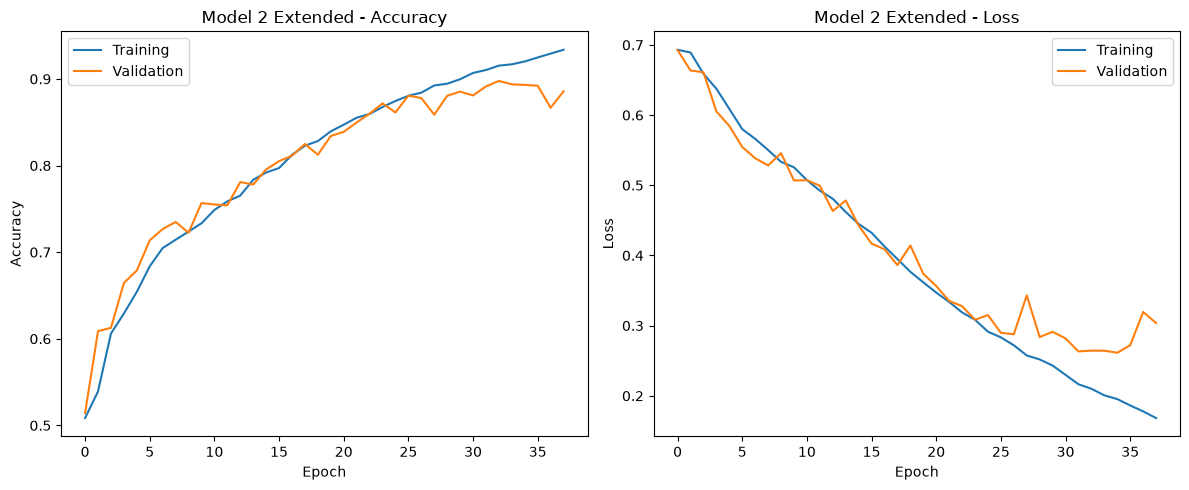

In [20]:
plt.figure(figsize = (12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_model_2_extended.history['accuracy'], label = 'Training')
plt.plot(history_model_2_extended.history['val_accuracy'], label = 'Validation')
plt.title('Model 2 Extended - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_model_2_extended.history['loss'], label = 'Training')
plt.plot(history_model_2_extended.history['val_loss'], label = 'Validation')
plt.title('Model 2 Extended - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [21]:
from keras.models import clone_model

model_3_extended = clone_model(model_2_extended)

model_3_extended.compile(loss = 'binary_crossentropy',
                         optimizer = RMSprop(learning_rate = 1e-4),
                         metrics = ['accuracy'])

model_3_extended.summary()
models.append("model_3_extended")

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_52 (Conv2D)                   │ (None, 150, 150, 16)        │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_53 (Conv2D)                   │ (None, 150, 150, 16)        │           2,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_54 (Conv2D)                   │ (None, 150, 150, 16)        │           2,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_20 (MaxPooling2D)      │ (None, 75, 75, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_55 (Conv2D)                   │ (None, 75, 75, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_56 (Conv2D)                   │ (None, 75, 75, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_57 (Conv2D)                   │ (None, 75, 75, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_21 (MaxPooling2D)      │ (None, 37, 37, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_58 (Conv2D)                   │ (None, 37, 37, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_59 (Conv2D)                   │ (None, 37, 37, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_60 (Conv2D)                   │ (None, 37, 37, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_22 (MaxPooling2D)      │ (None, 18, 18, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_61 (Conv2D)                   │ (None, 18, 18, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_62 (Conv2D)                   │ (None, 18, 18, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_63 (Conv2D)                   │ (None, 18, 18, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_23 (MaxPooling2D)      │ (None, 9, 9, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_5 (Flatten)                  │ (None, 10368)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 10368)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 256)                 │       2,654,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_16 (Dense)                     │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 3,177,089 (12.12 MB)

 Trainable params: 3,177,089 (12.12 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
es = EarlyStopping(patience = patience, monitor = 'val_accuracy', mode = 'max', restore_best_weights = True)

history_model_3_extended = model_3_extended.fit(
    train_generator_augmentation,
    epochs = epochs,
    validation_data = validation_generator,
    callbacks = [es]
)

history_model_3_extended_df = pd.DataFrame(history_model_3_extended.history)
history_model_3_extended_df.to_csv('history/history_model_3_extended.csv', index = False)

Epoch 1/1000
 50/274 ━━━━━━━━━━━━━━━━━━━━ 52s 234ms/step - accuracy: 0.5116 - loss: 0.6931

C:\Users\ayuru\AppData\Local\Programs\Python\Python314\Lib\site-packages\PIL\TiffImagePlugin.py:949: UserWarning: Truncated File Read
  warnings.warn(str(msg))


274/274 ━━━━━━━━━━━━━━━━━━━━ 69s 251ms/step - accuracy: 0.5090 - loss: 0.6930 - val_accuracy: 0.6104 - val_loss: 0.6918
Epoch 2/1000
274/274 ━━━━━━━━━━━━━━━━━━━━ 68s 249ms/step - accuracy: 0.5694 - loss: 0.6788 - val_accuracy: 0.6154 - val_loss: 0.6459
Epoch 3/1000
274/274 ━━━━━━━━━━━━━━━━━━━━ 68s 247ms/step - accuracy: 0.6151 - loss: 0.6512 - val_accuracy: 0.6186 - val_loss: 0.6401
Epoch 4/1000
274/274 ━━━━━━━━━━━━━━━━━━━━ 68s 248ms/step - accuracy: 0.6327 - loss: 0.6340 - val_accuracy: 0.6593 - val_loss: 0.6206
Epoch 5/1000
274/274 ━━━━━━━━━━━━━━━━━━━━ 68s 248ms/step - accuracy: 0.6597 - loss: 0.6112 - val_accuracy: 0.6841 - val_loss: 0.5911
Epoch 6/1000
274/274 ━━━━━━━━━━━━━━━━━━━━ 68s 247ms/step - accuracy: 0.6861 - loss: 0.5846 - val_accuracy: 0.7117 - val_loss: 0.5623
Epoch 7/1000
274/274 ━━━━━━━━━━━━━━━━━━━━ 68s 248ms/step - accuracy: 0.7051 - loss: 0.5647 - val_accuracy: 0.7239 - val_loss: 0.5473
Epoch 8/1000
274/274 ━━━━━━━━━━━━━━━━━━━━ 68s 247ms/step - accuracy: 0.7147 - loss

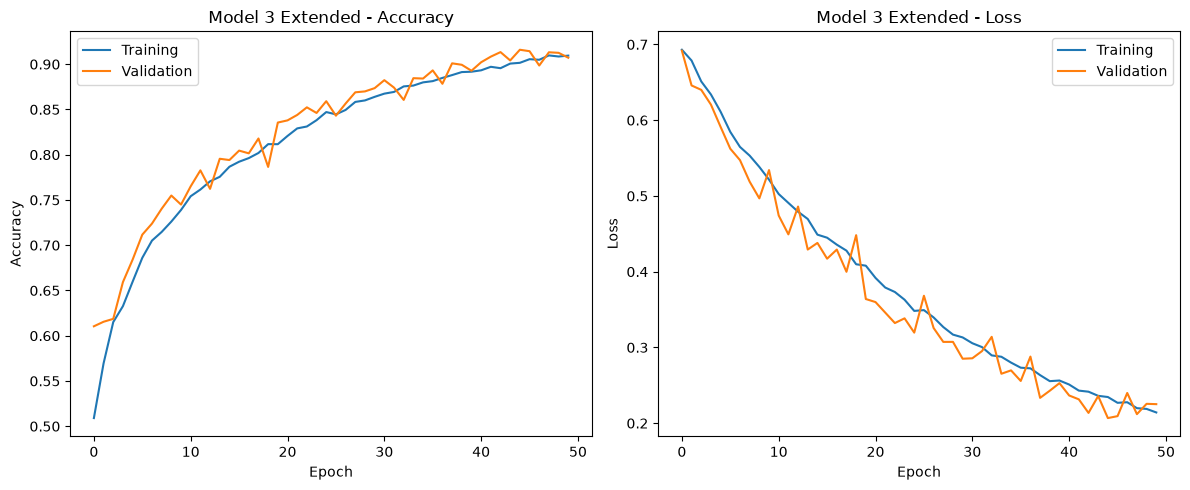

In [23]:
plt.figure(figsize = (12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_model_3_extended.history['accuracy'], label = 'Training')
plt.plot(history_model_3_extended.history['val_accuracy'], label = 'Validation')
plt.title('Model 3 Extended - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_model_3_extended.history['loss'], label = 'Training')
plt.plot(history_model_3_extended.history['val_loss'], label = 'Validation')
plt.title('Model 3 Extended - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [24]:
test_data_dir = 'dataset/test/'

test_generator = test_datagen.flow_from_directory(
    test_data_dir,
    target_size = (img_height, img_width),
    batch_size = batch_size,
    class_mode = 'binary',
    shuffle = False
)

Found 2502 images belonging to 2 classes.


In [27]:
results = []

for name, model in [
    ('Model 1', model_1_extended),
    ('Model 2', model_2_extended),
    ('Model 3', model_3_extended)
]:
    loss, accuracy = model.evaluate(test_generator, verbose = 0)
    results.append({'Model': name, 'Test accuracy': accuracy, 'Test loss': loss})

results_df = pd.DataFrame(results)
print(results_df.to_string(index = False))

  Model  Test accuracy  Test loss
Model 1       0.828138   0.382032
Model 2       0.890088   0.280449
Model 3       0.912470   0.204561


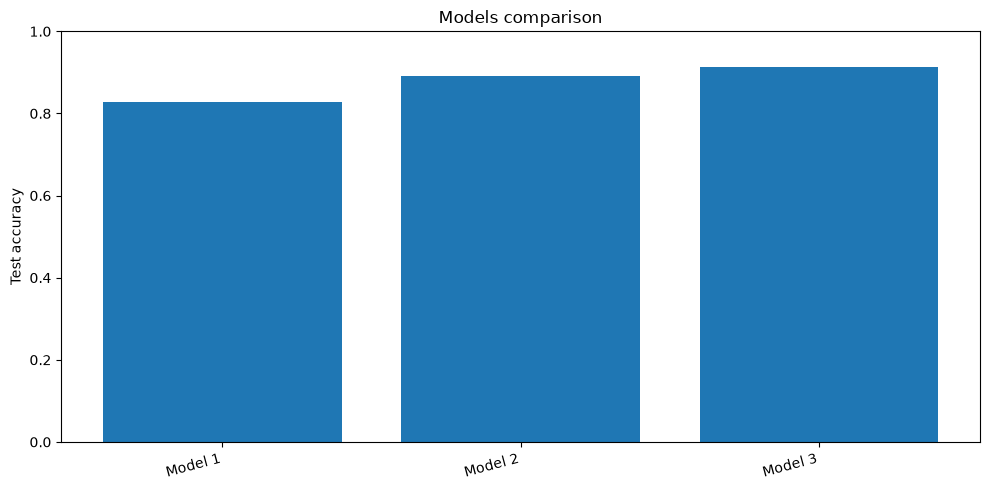

In [28]:
plt.figure(figsize = (10, 5))
plt.bar(results_df['Model'], results_df['Test accuracy'])
plt.title('Models comparison')
plt.ylabel('Test accuracy')
plt.ylim(0, 1)
plt.xticks(rotation = 15, ha = 'right')
plt.tight_layout()
plt.show()